# Bonus B5: How to build the desk agent with Microsoft Agent Framework

## Goal

We build the Chinook desk agent with Microsoft Agent Framework, then keep a refund request waiting for a person's decision across a process restart. The moment comes when we open a new Python process: it finds the pending review on disk, and only an approval adds the request to our local queue.

## What you will learn

- How to use the public model client before putting it inside an `Agent`.
- How to inspect the three read-only tools, messages and usage behind a desk answer.
- How to connect typed executor methods into an explicit workflow.
- How to save a pending review with `FileCheckpointStorage` and resume it in a new process.
- How to check approval, rejection and repeated delivery against the queue itself.
- When this framework fits better than the core path's Agents SDK and LangGraph.

## Setup

Run with this folder's isolated environment and an OpenAI key; the README gives the setup commands. Every object needed is built here; no other notebook has to run first. The config cell below finds the repository folder, the model settings and your key without printing the key; Lab 00 explains it line by line.

⚠️ Model cells make paid requests. The workflow uses invented refund requests and a local queue; it never sends money.

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


## Part A: Read one model response before using an agent

We first use [Microsoft's OpenAI client](https://learn.microsoft.com/en-us/agent-framework/integrations/by-component/model-providers/openai) directly on a question we can check by eye.

A `Message` contains a role and a list of contents. Here the role is `user` and the only content is text. `OpenAIChatClient` in this release uses OpenAI's **Responses API**. Its name alone does not identify the HTTP endpoint. We set `reasoning` from our settings and use the client's `max_tokens` option, which this adapter translates to `max_output_tokens`.

`await` waits for the network operation without blocking the notebook's event loop. Jupyter already runs that loop, so we use top-level `await`.

The 400-token output budget is a teaching choice, not the provider's maximum.

In [2]:
from agent_framework import Agent, Message, tool
from agent_framework.openai import OpenAIChatClient
from openai import omit

OPTIONS = {"reasoning": {"effort": EFFORT or omit}, "max_tokens": 400}
client = OpenAIChatClient(model=MODEL)
message = Message(role="user", contents=["Return only the sum of 2 and 3."])
print(message.to_dict())
print(type(client).__name__, OPTIONS)

{'type': 'message', 'role': 'user', 'contents': [{'type': 'text', 'text': 'Return only the sum of 2 and 3.', 'additional_properties': {}}], 'additional_properties': {}}
OpenAIChatClient {'reasoning': {'effort': 'none'}, 'max_tokens': 400}


In [3]:
small = await client.get_response([message], options=OPTIONS)
print(type(small).__name__, small.text)
print("usage:", small.usage_details)
print("provider result:", type(small.raw_representation).__name__)
print("provider usage:", small.raw_representation.usage)

ChatResponse 5
usage: {'cache_read_input_token_count': 0, 'input_token_count': 17, 'openai.cached_input_tokens': 0, 'reasoning_output_token_count': 0, 'cache_creation_input_token_count': 0, 'openai.reasoning_tokens': 0, 'output_token_count': 5, 'total_token_count': 22, 'openai.cache_write_tokens': 0}
provider result: Response
provider usage: ResponseUsage(input_tokens=17, input_tokens_details=InputTokensDetails(cache_write_tokens=0, cached_tokens=0), output_tokens=5, output_tokens_details=OutputTokensDetails(reasoning_tokens=0), total_tokens=22)


The result is a `ChatResponse`; `.text` extracts the assistant's text from its messages. The raw provider result is an OpenAI `Response`. The framework's `input_token_count` and `output_token_count` correspond to the provider's `input_tokens` and `output_tokens`. We can inspect both rather than infer cost from the length of the answer.

**Checkpoint A.** The answer is `5`, there is one assistant response, and the usage fields describe one provider request. No tools were offered. Now we can give this same client to an agent with database tools.

## Part B: Give the desk agent three read-only tools

The desk needs customer identity before it can look up invoices or a support rep. We read the public Chinook sample database in place. The connection's `mode=ro` blocks writes even if later code tries one; `check_same_thread=False` allows framework worker threads to use it.

The queries are fixed. SQLite substitutes each `?` with an argument value, so a model cannot turn a customer name into SQL. A customer search returns a list because a name can have zero or several matches. The other tools return dictionaries whose keys name the facts.

In [4]:
import sqlite3

DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)


def find_customer(name: str) -> list[dict]:
    """Find a shop customer by full name. Returns a list of matches with their customer_id.

    Args:
        name: First and last name, for example 'Ana Silva'.
    """
    rows = conn.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)).fetchall()
    return [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]


def get_invoices(customer_id: int) -> dict:
    """Count a customer's invoices and add up their total in US dollars."""
    count, total = conn.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": total}


def get_support_rep(customer_id: int) -> dict:
    """Name the support rep who looks after a customer."""
    row = conn.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "support_rep": row[0] if row else None}

In [5]:
customer = find_customer("Helena Holý")[0]
print(customer)
print(get_invoices(customer["customer_id"]))
print(get_support_rep(customer["customer_id"]))

{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}
{'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
{'customer_id': 6, 'support_rep': 'Steve Johnson'}


Helena is customer `6`, with `7` invoices totalling `$49.62`; Steve Johnson is her support rep. These are the answer key, checked without a model. Chinook is public, so the model may also know these facts from training. A correct sentence alone cannot prove that it looked them up.

`tool()` reads a function's name, docstring and type hints to describe it to the model. We wrap the three functions and inspect one tool before building the `Agent`.

`[0]` selects the first match from the list. We use it only after checking this exact name has one match.

In [6]:
tools = [tool(find_customer), tool(get_invoices), tool(get_support_rep)]
print(tools[0].to_dict())
print("registered:", [t.name for t in tools])

{'type': 'function_tool', 'name': 'find_customer', 'description': "Find a shop customer by full name. Returns a list of matches with their customer_id.\n\nArgs:\n    name: First and last name, for example 'Ana Silva'.\n", 'approval_mode': 'never_require', 'invocation_count': 0, 'invocation_exception_count': 0, 'input_model': {'properties': {'name': {'title': 'Name', 'type': 'string'}}, 'required': ['name'], 'title': 'find_customer_input', 'type': 'object'}}
registered: ['find_customer', 'get_invoices', 'get_support_rep']


The generated schema gives `name` a string type. A tool call supplies arguments for our registered Python function; it does not let the model execute arbitrary Python. The framework invokes the function and sends its return value back to the model.

We now construct the public `Agent` directly. Instructions tell it to look up the customer first and obtain all requested facts from tools. `default_options` carries the same effort and output budget as our direct call. The tools remain read-only; the later refund workflow is separate.

In [7]:
desk = Agent(
    client=client, name="Desk",
    instructions=("You are the Chinook music shop support desk. Use the tools for customer facts. "
                  "Find the customer by full name first, then fetch the requested invoice and rep facts. "
                  "Do not answer from memory. Reply briefly and include all requested facts."),
    tools=tools, default_options=OPTIONS,
)
print(type(desk).__name__, desk.name)
print("tools:", [t.name for t in tools])

Agent Desk
tools: ['find_customer', 'get_invoices', 'get_support_rep']


**Checkpoint B.** All three functions work before the agent uses them. The registered names are `find_customer`, `get_invoices` and `get_support_rep`. The agent contains one client, instructions and these three tools. We next inspect a complete run to see the loop that this object packages.

## Part C: Read the agent's calls and cost

An agent call can make several model requests. We attach a **chat middleware** observer so each returned provider call gets a ledger row. Middleware runs around a library operation: `await call_next()` lets the request finish, then `context.result` holds its response. This observer changes no messages and sends nothing to a tracing service.

The provider usage includes ordinary input, cache reads and cache writes. We subtract the latter two from total input before pricing them separately. Output tokens include reasoning where the provider reports it. Prices come from the shared settings, so changing models also changes the price assumptions.

In [8]:
from agent_framework import ChatMiddleware, ChatContext
from time import perf_counter

calls = []

class CallLedger(ChatMiddleware):
    async def process(self, context: ChatContext, call_next):
        started = perf_counter()
        await call_next()
        usage = context.result.raw_representation.usage
        details = usage.input_tokens_details
        cached = details.cached_tokens or 0
        written = getattr(details, "cache_write_tokens", 0) or 0
        cost = ((usage.input_tokens - cached - written) * float(settings["PRICE_INPUT_PER_MILLION"])
                + cached * float(settings["PRICE_CACHED_INPUT_PER_MILLION"])
                + written * float(settings["PRICE_CACHE_WRITE_PER_MILLION"])
                + usage.output_tokens * float(settings["PRICE_OUTPUT_PER_MILLION"])) / 1_000_000
        calls.append({"input": usage.input_tokens, "output": usage.output_tokens,
                      "cached": cached, "written": written, "usd": cost,
                      "seconds": round(perf_counter() - started, 3)})

The small direct call already showed the response and its usage fields; the observer now repeats that reading for each request hidden inside the agent loop. `middleware=` on `run` scopes it to this run. We keep the original agent and tool wiring.

In [9]:
QUESTION = "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?"
calls.clear()
started = perf_counter()
answer = await desk.run(QUESTION, middleware=[CallLedger()])
elapsed = perf_counter() - started
print(type(answer).__name__)
print(answer.text)
for i, row in enumerate(calls, 1):
    print("call", i, {**row, "usd": round(row["usd"], 7)})
print("total:", {"calls": len(calls), "input": sum(r["input"] for r in calls),
                 "output": sum(r["output"] for r in calls),
                 "usd": round(sum(r["usd"] for r in calls), 7), "seconds": round(elapsed, 3)})

AgentResponse
Helena Holý has **7 invoices**, totaling **$49.62**. Her support rep is **Steve Johnson**.
call 1 {'input': 227, 'output': 21, 'cached': 0, 'written': 0, 'usd': 3.32e-05, 'seconds': 1.642}
call 2 {'input': 287, 'output': 52, 'cached': 0, 'written': 0, 'usd': 5.47e-05, 'seconds': 1.751}
call 3 {'input': 398, 'output': 30, 'cached': 0, 'written': 0, 'usd': 5.48e-05, 'seconds': 1.768}
total: {'calls': 3, 'input': 912, 'output': 103, 'usd': 0.0001427, 'seconds': 5.166}


One agent run made three provider requests, and each got a ledger row; the request inputs grow (227, 287, 398 tokens) because every request resends the conversation so far, tool results included. The `total` row adds them up. We round each dollar figure to seven decimals when printing, because a float such as 0.0000548 can otherwise print with trailing binary rounding noise. Next we print the messages the run produced, to see which tool calls sit behind those three requests.

In [10]:
for message in answer.messages:
    print(message.to_dict())
print("framework total usage:", answer.usage_details)

{'type': 'message', 'role': 'assistant', 'contents': [{'type': 'function_call', 'call_id': 'call_tBQsCNTge5QPXVgdRGaNWAuf', 'name': 'find_customer', 'arguments': '{"name":"Helena Holý"}', 'status': 'completed', 'hosted': False, 'id': 'af-call-afc7d0e4aad94f8f8e5b8ed9e4462662', 'additional_properties': {'openai': {'item_id': 'fc_0097f68d62a3e0db006aec6079dc6487d2824f0a20c78f6d27'}, 'fc_id': 'fc_0097f68d62a3e0db006aec6079dc6487d2824f0a20c78f6d27', 'status': 'completed'}}], 'author_name': 'Desk', 'additional_properties': {}}
{'type': 'message', 'role': 'tool', 'contents': [{'type': 'function_result', 'call_id': 'call_tBQsCNTge5QPXVgdRGaNWAuf', 'result': '[{"customer_id": 6, "name": "Helena Hol\\u00fd", "country": "Czech Republic"}]', 'items': [{'type': 'text', 'text': '[{"customer_id": 6, "name": "Helena Hol\\u00fd", "country": "Czech Republic"}]', 'additional_properties': {}}], 'id': 'af-call-afc7d0e4aad94f8f8e5b8ed9e4462662', 'additional_properties': {'openai': {'item_id': 'fc_0097f68d6

Read the messages in order. An assistant `function_call` carries the tool name and arguments; a `function_result` carries our code's returned data. The last assistant text combines the three facts. Several tools may be requested in the same model reply, so tool-call count and provider-request count need not match.

In this saved run: **3 provider requests**, **912 input tokens**, **103 output tokens**, and **$0.0001427** at the configured prices. Timing is one observation on this network, not a framework ranking. The raw usage retains cache accounting; the aggregate framework usage is a useful reconciliation.

We check both the answer and the actual tool names. The text check is deliberately small: it recognises the expected number and phrases, not every possible correct wording.

The nested loops in the next cell visit every message, then every content item within that message. The filter keeps only function calls; `content.name` records which registered function was requested.
The matching `call_id` links each returned tool result to the model request that asked for it. `to_dict()` exposes the message fields as ordinary Python dictionaries.


In [11]:
import re

used_tools = [content.name for message in answer.messages for content in message.contents
              if content.type == "function_call"]
facts_ok = bool(re.search(r"\b7\b", answer.text)) and "49.62" in answer.text and "Steve Johnson" in answer.text
print("tool path:", used_tools)
print("facts correct:", facts_ok)
print("all tools used:", set(used_tools) == {t.name for t in tools})
assert facts_ok and set(used_tools) == {t.name for t in tools}
assert sum(r["input"] for r in calls) == answer.usage_details["input_token_count"]
assert sum(r["output"] for r in calls) == answer.usage_details["output_token_count"]

tool path: ['find_customer', 'get_invoices', 'get_support_rep']
facts correct: True
all tools used: True


### What the whole notebook spent on the model

The desk run is not the only model work: Part A made one direct request. Its usage printed 0 cached and 0 written input tokens, so its input and output prices are enough. Parts D to F make no model calls, so these two figures together are the notebook's whole model cost.

In [12]:
# The Part A call: no cached or written input (its usage printed both as 0)
small_usage = small.raw_representation.usage
small_usd = (small_usage.input_tokens * float(settings["PRICE_INPUT_PER_MILLION"])
             + small_usage.output_tokens * float(settings["PRICE_OUTPUT_PER_MILLION"])) / 1_000_000
desk_usd = sum(row["usd"] for row in calls)
print(f"Part A call: ${small_usd:.7f}")
print(f"Part C desk run: ${desk_usd:.7f}")
print(f"whole notebook: ${small_usd + desk_usd:.7f}")

Part A call: $0.0000042
Part C desk run: $0.0001427
whole notebook: $0.0001469


The direct call cost $0.0000042, so the whole notebook spent $0.0001469 on the model; the desk run is almost all of it.

**Checkpoint C.** All three tools appear and the answer contains 7 invoices, $49.62 and Steve Johnson. The per-request input and output sums match the framework's totals.

The agent lets the model choose its next tool. A refund approval needs a different owner for that decision: explicit Python transitions. We now stop making model calls.

## Part D: Make the refund transitions explicit

We want a request to wait for a person before any queue write. We use three **executors**, framework objects with typed handler methods: check eligibility, ask a person, then queue the approved request. A workflow connects their outputs with edges.

The input below is an invented duplicate-charge claim for teaching. `request_id` identifies the action, `customer_id` identifies the sample customer, `amount` is US dollars, and `duplicate_confirmed` stands for an earlier investigation. Our toy rule accepts a confirmed duplicate above zero and at most $50. It is not a real shop policy or proof that any duplicate exists.

In [13]:
request = {"request_id": "demo-approved", "customer_id": 6,
           "amount": 9.99, "duplicate_confirmed": True}
print(request)

{'request_id': 'demo-approved', 'customer_id': 6, 'amount': 9.99, 'duplicate_confirmed': True}


The executor code lives in `refund_workflow.py` so a new Python process can import the same definitions. We read each class here before constructing it. The decorators register methods: `@handler` receives workflow messages; `@response_handler` receives an external response paired with its original request.

`ctx.send_message()` sends data along an edge. `ctx.yield_output()` produces a workflow result. `ctx.request_info(..., response_type=bool)` records a pending question and returns control to our application. It does not approve anything by itself.
`sys.path.insert(0, str(LAB))` lets both notebooks import the same module, including when the solution is opened from its own folder.


In [14]:
import inspect
import sys

LAB = ROOT / "bonus" / "B5_Microsoft_Agent_Framework"
sys.path.insert(0, str(LAB))
from refund_workflow import CheckRequest, HumanReview, QueueRequest

print(inspect.getsource(CheckRequest))

class CheckRequest(Executor):
    @handler
    async def check(self, request: dict, ctx: WorkflowContext[dict, dict]):
        # This small teaching policy is invented; it is not Chinook shop policy.
        if request['duplicate_confirmed'] and 0 < request['amount'] <= 50:
            await ctx.send_message(request)
        else:
            await ctx.yield_output({'request_id': request['request_id'], 'status': 'ineligible'})



`CheckRequest` accepts a dictionary. Eligible input moves to the next executor; ineligible input produces a result and stops that path. The `WorkflowContext[dict, dict]` annotation says that outgoing messages and workflow results are dictionaries. We use built-in types so the checkpoint contains simple data.

In [15]:
print(inspect.getsource(HumanReview))

class HumanReview(Executor):
    @handler
    async def ask(self, request: dict, ctx: WorkflowContext[dict, dict]):
        await ctx.request_info(request_data=request, response_type=bool)

    @response_handler
    async def decide(self, original_request: dict, response: bool,
                     ctx: WorkflowContext[dict, dict]):
        if response:
            await ctx.send_message(original_request)
        else:
            await ctx.yield_output({'request_id': original_request['request_id'], 'status': 'rejected'})



The review request contains the amount and customer the person is asked to review. On a `True` response, the original request moves to the queue. On `False`, the workflow yields `rejected` without sending a message to the queue. The application owns the boolean; a production UI must authenticate and authorise the person supplying it.

In [16]:
print(inspect.getsource(QueueRequest))

class QueueRequest(Executor):
    def __init__(self, queue_path: Path):
        super().__init__(id='queue')
        self.queue_path = queue_path
        with sqlite3.connect(queue_path) as db:
            db.execute('CREATE TABLE IF NOT EXISTS requests '
                       '(request_id TEXT PRIMARY KEY, customer_id INTEGER, amount REAL)')

    @handler
    async def queue(self, request: dict, ctx: WorkflowContext[dict, dict]):
        with sqlite3.connect(self.queue_path) as db:
            db.execute('INSERT OR IGNORE INTO requests VALUES (?, ?, ?)',
                       (request['request_id'], request['customer_id'], request['amount']))
        await ctx.yield_output({'request_id': request['request_id'], 'status': 'queued'})



The queue is our system of record for this exercise. `request_id` is a primary key, so replaying the same approved action cannot add a second row. `INSERT OR IGNORE` is a small idempotency example: repeat delivery has the same effect. It does not protect a real payment API, and a reused ID with different details would need explicit conflict handling in a real service.

We construct the public workflow directly before using a factory. A fresh directory under gitignored `outputs/` gives each notebook run a separate checkpoint store and queue. `tempfile.mkdtemp` creates it; nothing in `data/` changes.

In [17]:
from agent_framework import WorkflowBuilder, FileCheckpointStorage
import tempfile

LAB = ROOT / "bonus" / "B5_Microsoft_Agent_Framework"
(LAB / "outputs").mkdir(exist_ok=True)
RUN = Path(tempfile.mkdtemp(prefix="refund-", dir=LAB / "outputs"))
check = CheckRequest(id="check")
review = HumanReview(id="review")
queue = QueueRequest(RUN / "queue.db")
storage = FileCheckpointStorage(RUN / "checkpoints")
builder = WorkflowBuilder(name="refund", start_executor=check, checkpoint_storage=storage)
builder.add_edge(check, review)
builder.add_edge(review, queue)
workflow = builder.build()
print(type(workflow).__name__, "check -> review -> queue")

Workflow check -> review -> queue


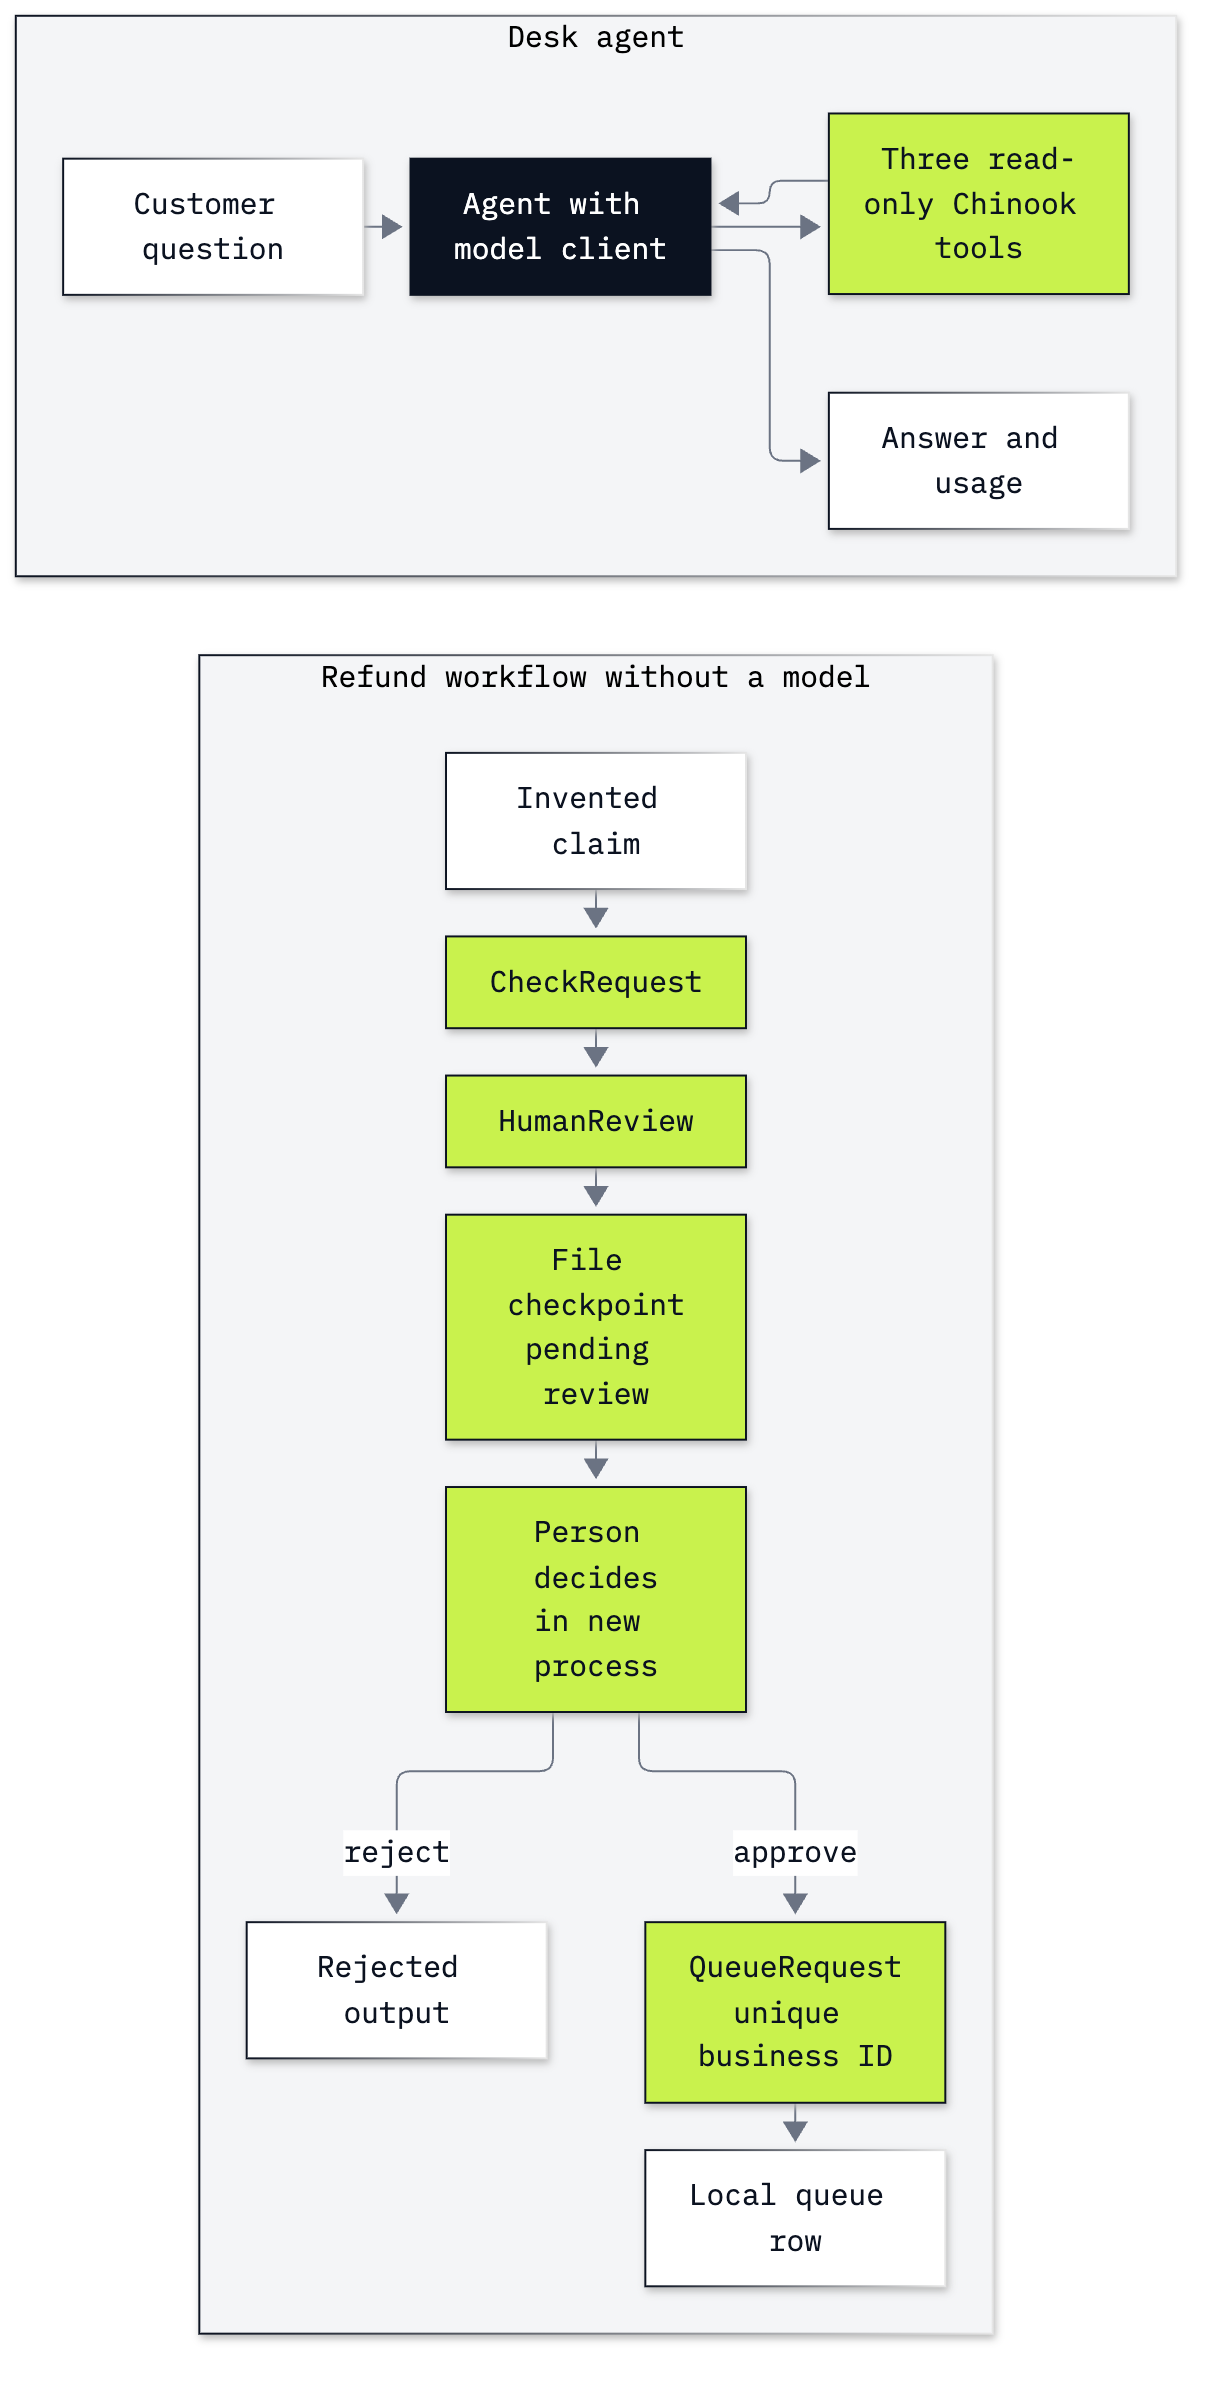

In [18]:
from IPython.display import Image, display

display(Image(filename=str(LAB / "resources" / "labB5_agent_and_workflow.png"), width=760))

The upper path is the desk agent's model-selected loop. The lower path is our code-selected refund workflow: a pending request separates the check from the queue. Ink means a model chooses; lime means our code controls the transition or write.

**Checkpoint D.** The graph is `check → review → queue`. All three executor classes are visible, and the queue writes only a local database. No model client appears in this workflow.

## Part E: Restore the waiting review in a new process

[File checkpoints](https://learn.microsoft.com/en-us/agent-framework/workflows/checkpoints) save workflow position and pending requests between supersteps, the rounds in which ready executors run. We start the request and stop at the review. Predict the queue size before running: no response has been supplied yet.

In [19]:
paused = await workflow.run(request)
for event in paused:
    if event.type in {"executor_invoked", "request_info", "output"}:
        print(event.type, event.executor_id, event.data)
pending = paused.get_request_info_events()
checkpoint = await storage.get_latest(workflow_name="refund")
with sqlite3.connect(RUN / "queue.db") as db:
    print("queue before review:", db.execute("SELECT COUNT(*) FROM requests").fetchone()[0])
print("pending reviews:", len(pending))
print("checkpoint saved:", checkpoint is not None)
assert len(pending) == 1 and checkpoint is not None

executor_invoked check {'request_id': 'demo-approved', 'customer_id': 6, 'amount': 9.99, 'duplicate_confirmed': True}
executor_invoked review {'request_id': 'demo-approved', 'customer_id': 6, 'amount': 9.99, 'duplicate_confirmed': True}
request_info None {'request_id': 'demo-approved', 'customer_id': 6, 'amount': 9.99, 'duplicate_confirmed': True}
queue before review: 0
pending reviews: 1
checkpoint saved: True


The request event contains our invented claim. There is one pending review and zero queue rows. The latest checkpoint belongs to the paused graph; we retain its ID so later runs do not accidentally choose a newer checkpoint.

A checkpoint differs from conversation history. The desk's messages contain the question, tool calls and answer. This workflow checkpoint contains execution state, messages waiting on edges and the pending review. It can restore this workflow without any model conversation.

⚠️ Restore only checkpoints your application wrote in trusted storage. They are application state, and the storage may decode Python objects. Keep the same compatible graph and executor IDs when reconstructing a run.

We now read the factory. It packages exactly the construction just run, returning `(workflow, storage)` so a new process can recreate the graph without the notebook's live objects.

In [20]:
from refund_workflow import build_workflow, resume

print(inspect.getsource(build_workflow))
print(inspect.getsource(resume))

def build_workflow(run_dir: Path):
    """Recreate the same graph and executor IDs used in the notebook."""
    check = CheckRequest(id='check')
    review = HumanReview(id='review')
    queue = QueueRequest(run_dir / 'queue.db')
    storage = FileCheckpointStorage(run_dir / 'checkpoints')
    builder = WorkflowBuilder(name='refund', start_executor=check, checkpoint_storage=storage)
    builder.add_edge(check, review)
    builder.add_edge(review, queue)
    return builder.build(), storage

async def resume(run_dir: Path, checkpoint_id: str, decision: bool):
    workflow, storage = build_workflow(run_dir)
    restored = await workflow.run(checkpoint_id=checkpoint_id)
    pending = restored.get_request_info_events()
    assert len(pending) == 1, 'Expected one pending review.'
    result = await workflow.run(responses={pending[0].request_id: decision})
    with sqlite3.connect(run_dir / 'queue.db') as db:
        rows = db.execute('SELECT * FROM requests ORDER BY request_id').fetchall()
 

`resume()` restores the saved checkpoint first. The framework re-emits the pending request; its `request_id` is the routing key for the response dictionary passed to `workflow.run(responses=...)`. This event ID is separate from our business `request_id`, which prevents duplicate queue entries.

The short `resume_refund.py` entry point imports `resume` from the same module as the notebook. Keeping the executor classes in that importable module preserves their identity across processes. We launch this entry point with `sys.executable`, so the child uses the same isolated Python environment. The child imports the module, constructs fresh executors and opens the checkpoint files. It receives only a directory, checkpoint ID and our decision. The final JSON line contains its outputs and actual queue rows.

`check=True` makes a failed child process raise an exception. `capture_output=True, text=True` captures its printed JSON as text; `json.loads` turns it back into a dictionary. The child imports no model settings or key.

In [21]:
import subprocess
import sys
import json

completed = subprocess.run(
    [sys.executable, str(LAB / "resume_refund.py"), str(RUN), checkpoint.checkpoint_id, "approve"],
    check=True, capture_output=True, text=True,
)
approved = json.loads(completed.stdout)
print("new process:", approved["pid"] != os.getpid())
print("restored reviews:", approved["restored_requests"])
print("workflow outputs:", approved["outputs"])
print("queue:", approved["queue"])
assert approved["pid"] != os.getpid()
assert approved["queue"] == [["demo-approved", 6, 9.99]]

new process: True
restored reviews: 1
workflow outputs: [{'request_id': 'demo-approved', 'status': 'queued'}]
queue: [['demo-approved', 6, 9.99]]


The new process found one waiting review. Approval reached `QueueRequest`, and the queue holds the same customer and amount that the person reviewed. `queued` means a local refund request was filed; no refund was paid.

We now repeat the same approval from the same old checkpoint. A workflow checkpoint alone cannot promise that a side effect runs only once. Our queue's unique business ID should keep the row count at one.

In [22]:
completed = subprocess.run(
    [sys.executable, str(LAB / "resume_refund.py"), str(RUN), checkpoint.checkpoint_id, "approve"],
    check=True, capture_output=True, text=True,
)
replayed = json.loads(completed.stdout)
print("queue after repeated approval:", replayed["queue"])
assert replayed["queue"] == approved["queue"]

queue after repeated approval: [['demo-approved', 6, 9.99]]


Rejection must also be tested, using a separate business ID. The factory is now useful because we have already built and run the graph directly. The second request uses the same store and queue, but creates a new workflow run. We again keep the checkpoint ID from its paused review.

`{**request, "request_id": ...}` copies the existing fields into a new dictionary, then replaces the ID. The first request remains unchanged.

In [23]:
second, second_storage = build_workflow(RUN)
rejected_request = {**request, "request_id": "demo-rejected"}
second_pause = await second.run(rejected_request)
second_checkpoint = await second_storage.get_latest(workflow_name="refund")
completed = subprocess.run(
    [sys.executable, str(LAB / "resume_refund.py"), str(RUN), second_checkpoint.checkpoint_id, "reject"],
    check=True, capture_output=True, text=True,
)
rejected = json.loads(completed.stdout)
print("workflow outputs:", rejected["outputs"])
print("queue after rejection:", rejected["queue"])
assert rejected["outputs"] == [{"request_id": "demo-rejected", "status": "rejected"}]
assert rejected["queue"] == approved["queue"]

workflow outputs: [{'request_id': 'demo-rejected', 'status': 'rejected'}]
queue after rejection: [['demo-approved', 6, 9.99]]


**Checkpoint E.** Before review: zero queue rows. After approval in a new process: one row for `demo-approved`. Repeating that approval leaves one row. Rejecting `demo-rejected` produces `rejected` and leaves the queue unchanged.

These checks inspect the stored effect rather than trust the final message. In production, the application must also own reviewer permissions, policy evidence, storage access and conflict handling.

## Part F: Map an inherited AutoGen system to this design

If you inherit AutoGen code, start by identifying which component owns each decision. The [official migration guide](https://learn.microsoft.com/en-us/agent-framework/migration-guide/from-autogen/) compares the APIs; this small map connects the concepts we just ran.

| Inherited AutoGen concept | Here | Responsibility to preserve |
|---|---|---|
| `AssistantAgent` with a model client | `Agent` with `OpenAIChatClient` | Instructions, tools and model options |
| A team's message routing | Executors and explicit workflow edges, or an orchestration builder | Who selects the next participant or step |
| Tool request and execution events | Function-call and result contents in messages | Arguments, execution and returned evidence |
| A human-input or termination point | `request_info` and a response handler | Who may continue the operation |
| Saved team state | Conversation state or workflow checkpoints, according to the task | What is restored and which code is compatible |

This is a design map, not a stored-state conversion. Do not assume an AutoGen `save_state()` payload loads into a framework checkpoint. Rebuild one representative case, compare its messages and effects, and keep behavioural checks such as the queue checks above.

**Checkpoint F.** Explain why the desk agent chooses its own tool sequence, while the refund workflow always waits at `review`. Which part of an inherited system should become a model decision, and which should remain an explicit transition?

## When to use it

The core path builds the desk agent in lab 07 (the Agents SDK) and pauses a refund for approval in lab 10 (LangGraph); bonus B1 makes a LangGraph workflow survive a restart. Microsoft Agent Framework does both jobs in one library, with two different owners for the next step: in Part C the model chose the tools (3 provider requests, 912 input and 103 output tokens, $0.0001427), and in Parts D and E our code chose every transition, with no model at all. The waiting review survived in file checkpoints and a new process approved it into one queue row. Replaying that approval left one row, but that came from the queue's primary key, not from the checkpoint: restoring can repeat a side effect, so the write still needs its own business key. Choose this framework when you inherit AutoGen code (Part F) or your team builds on Microsoft's stack and wants the agent and the workflow from one vendor. If you start from the core path, lab 07's SDK for the agent and LangGraph (lab 10, B1) for the durable workflow give the same two shapes.

## What you can do now

You can construct and inspect a framework client and agent, read its tool loop and price its provider calls. You can also build a workflow from typed executor methods, checkpoint a human review, reconstruct it in another process, and check its approval or rejection against a stored queue.

## Challenge

1. Submit a confirmed duplicate for `$75` with business ID `demo-over-limit`. Use a fresh graph from `build_workflow(RUN)`. Expect `ineligible`, zero pending reviews and no new queue row.
2. Submit `$12.50` with ID `demo-challenge`, pause, reconstruct the graph, and reject it. Expect one restored review, a `rejected` output and an unchanged queue.

Use the same toy policy. Do not add a model to decide eligibility. The [full solved notebook](b5_microsoft_agent_framework_solution.ipynb) runs the same setup and solves both tasks.

In [24]:
over_limit, _ = build_workflow(RUN)
invalid = await over_limit.run({**request, "request_id": "demo-over-limit", "amount": 75.0})
print("over limit:", invalid.get_outputs())
print("pending reviews:", len(invalid.get_request_info_events()))
assert invalid.get_outputs() == [{"request_id": "demo-over-limit", "status": "ineligible"}]
assert not invalid.get_request_info_events()

challenge, challenge_storage = build_workflow(RUN)
waiting = await challenge.run({**request, "request_id": "demo-challenge", "amount": 12.50})
saved = await challenge_storage.get_latest(workflow_name="refund")
completed = subprocess.run(
    [sys.executable, str(LAB / "resume_refund.py"), str(RUN), saved.checkpoint_id, "reject"],
    check=True, capture_output=True, text=True,
)
challenge_result = json.loads(completed.stdout)
print("restored reviews:", challenge_result["restored_requests"])
print("challenge outputs:", challenge_result["outputs"])
print("queue:", challenge_result["queue"])
assert challenge_result["outputs"] == [{"request_id": "demo-challenge", "status": "rejected"}]
assert challenge_result["queue"] == approved["queue"]

over limit: [{'request_id': 'demo-over-limit', 'status': 'ineligible'}]
pending reviews: 0


restored reviews: 1
challenge outputs: [{'request_id': 'demo-challenge', 'status': 'rejected'}]
queue: [['demo-approved', 6, 9.99]]


The $75 request finishes at the eligibility check, so it creates no pending review. The $12.50 request restores one review in a new process and ends as `rejected`. The only queue row is still the earlier approved $9.99 request; neither challenge added a row.


## Resources

- [OpenAI provider](https://learn.microsoft.com/en-us/agent-framework/integrations/by-component/model-providers/openai): model-client choices and options.
- [Workflow human input](https://learn.microsoft.com/en-us/agent-framework/workflows/human-in-the-loop): `request_info`, typed responses and restored requests.
- [Workflow checkpoints](https://learn.microsoft.com/en-us/agent-framework/workflows/checkpoints): storage, restoration and trust boundaries.
- [AutoGen migration guide](https://learn.microsoft.com/en-us/agent-framework/migration-guide/from-autogen/): API and ownership changes.
- [OpenAI function calling](https://developers.openai.com/api/docs/guides/function-calling): tool requests, execution and results.
- [Python subprocess](https://docs.python.org/3/library/subprocess.html): starting and checking a child process.

Back to [the bonus lab list](../../README.md).